In [433]:
import numpy as np
from scipy.special import erf
from scipy.stats import norm
from scipy.linalg import expm, solve_continuous_lyapunov, inv, kron, logm

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyArrow
from matplotlib.legend_handler import HandlerPatch
from matplotlib.ticker import MaxNLocator
from matplotlib.gridspec import GridSpec

from __future__ import annotations
from collections import deque
from dataclasses import dataclass
from typing import Callable, Tuple, Optional, Literal
 
from tqdm import tqdm

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{lmodern}"
}) 

#high contrast
separatrix_color = '#B22222'   
ccn_color = '#007f9d'          
controlled_region_color = "#1a72cf"
committor_region_color = "#00530e"

In [434]:
def generate_initial_conditions(n, bound, circle=False, along_stable=None, angle_range=np.pi/8, angle_distribution='uniform'):
    """
    Generate initial conditions for trajectories.
    If `circle` is True, points are uniformly distributed on a circle of radius `bound`.
    If a vector is provided for `along_stable`, points are uniformly distributed along the stable eigenvector direction on the circle.
    """
    if circle:
        if np.any(along_stable != None):
            along_stable_angle = np.arctan2(along_stable[1], along_stable[0])
            if angle_distribution == 'normal':
                angles_1 = np.random.normal(along_stable_angle, angle_range, int(n/2))
                angles_2 = np.random.normal(along_stable_angle + np.pi, angle_range, int(n/2))
            else:
                angles_1 = np.random.uniform(along_stable_angle - angle_range, along_stable_angle + angle_range, int(n/2))
                angles_2 = np.random.uniform(along_stable_angle + np.pi - angle_range, along_stable_angle + np.pi + angle_range, int(n/2))
            angles = np.concatenate((angles_1, angles_2))
            return np.array([bound * np.cos(angles), bound * np.sin(angles)]).T
        else:
            angles = np.random.uniform(0, 2 * np.pi, n)
            return np.array([bound * np.cos(angles), bound * np.sin(angles)]).T
    else:
        return np.random.uniform(-bound, bound, (n, 2))
    
    
def stopping_condition(x, bound, circle=False):
    norm_x = np.linalg.norm(x)
    if circle:
        return norm_x >= bound
    else:
        return np.all(np.abs(x) >= bound)


def simulate_euler_maruyama(drift_func, x0, t_span, dt, noise_std=0.0, **kwargs):
    """
    Simulate an SDE using the Euler–Maruyama method.
    
    Parameters:
        drift_func: Callable representing the deterministic drift f(x, **kwargs)
        x0: Initial state (array-like)
        t_span: Tuple (t0, t1)
        dt: Time step
        noise_std: Standard deviation (scalar or vector) of additive noise
        **kwargs: Additional arguments to pass to drift_func

    Returns:
        t_vals: Time values (numpy array)
        traj: Simulated trajectory (numpy array of shape [len(t_vals), len(x0)])
    """
    t_vals = np.arange(t_span[0], t_span[1] + dt, dt)
    traj = np.zeros((len(t_vals), len(x0)))
    traj[0] = x0

    sqrt_dt = np.sqrt(dt)

    for i in range(1, len(t_vals)):
        x = traj[i - 1]
        drift = drift_func(x)
        noise = np.random.normal(0, 1, size=x.shape) * noise_std * sqrt_dt
        traj[i] = x + drift * dt + noise

    # Check stopping condition
        if stopping_condition(traj[i], kwargs.get('bound', 1.0), kwargs.get('circle')):
            traj = traj[:i + 1]  # truncate trajectory to the last valid point
            t_vals = t_vals[:i + 1]
            break

    return t_vals, traj

def simulate_euler_maruyama_control(drift_func, control_func, x0, t_span, dt, noise_std=0.0, **kwargs):
    """
    Simulate an SDE with control using the Euler–Maruyama method.
    
    Parameters:
        drift_func: Callable representing the deterministic drift f(x, **kwargs)
        control_func: Callable representing the control u(t, x, **kwargs)
        x0: Initial state (array-like)
        t_span: Tuple (t0, t1)
        dt: Time step
        noise_std: Standard deviation (scalar or vector) of additive noise
        **kwargs: Additional arguments to pass to drift_func and control_func

    Returns:
        t_vals: Time values (numpy array)
        traj: Simulated trajectory (numpy array of shape [len(t_vals), len(x0)])
        controls: Control inputs at each time step (numpy array of shape [len(t_vals), len(x0)])
    """
    t_vals = np.arange(t_span[0], t_span[1] + dt, dt)
    traj = np.zeros((len(t_vals), len(x0)))
    traj[0] = x0
    controls = np.zeros((len(t_vals), len(x0)))

    sqrt_dt = np.sqrt(dt)

    for i in range(1, len(t_vals)):
        x = traj[i - 1]
        drift = drift_func(x)
        control = control_func(t_vals[i], x, **kwargs)
        noise = np.random.normal(0, 1, size=x.shape) * noise_std * sqrt_dt
        traj[i] = x + drift * dt + control * dt + noise
        controls[i] = control

    # Check stopping condition
        if stopping_condition(traj[i], kwargs.get('bound', 1.0), kwargs.get('circle')):
            traj = traj[:i + 1] 
            t_vals = t_vals[:i + 1]
            break

    return t_vals, traj, controls

def dddc_control(t, x, traj, controls, control_vector, **kwargs):
    """
    Compute the control input for the DD-DC controller.
    
    Parameters:
        t: Current time (not used in this implementation)
        x: Current state (numpy array)
        A: System matrix
        **kwargs: Additional arguments (not used in this implementation)

    Returns:
        Control input (numpy array)
    """
    if t < kwargs.get('t_start', 0):
        return np.random.normal(0, 1, size=x.shape) * kwargs['control_noise_std']
    traj_proj = np.dot(traj, control_vector) 
    X = traj_proj[:-1,:]
    X_next = traj_proj[1:,:]
    controls_proj = np.dot(controls, control_vector)
    w_star = get_w_star(X, X_next, controls_proj)
    
    return w_star*control_vector + np.random.normal(0, 1, size=x.shape) * kwargs['control_noise_std']

def get_w_star(X, X_next, controls):
    """
    Compute the optimal control input w_star for the DD-DC controller.
    
    Parameters:
        X: Current state trajectory (numpy array)
        X_next: Next state trajectory (numpy array)
        control_vector: Control vector (numpy array)
    Returns:
        w_star: Optimal control input scalar 

    """
    x_p_x_p = np.dot(X_next, X_next.T)
    cos_xx = 1/(x_p_x_p) * np.dot(X_next, X.T)
    w_star = np.dot(controls, X) - np.dot(controls, X_next) * cos_xx
    w_star /= (np.dot(X, X.T) - np.dot(X, X_next.T) * x_p_x_p)
    return w_star


def estimate_A_cov(X: np.ndarray) -> np.ndarray:
    """
    Estimate dynamics matrix A from trajectory snapshots using covariance method.

    Parameters
    ----------
    X : np.ndarray
        State trajectory of shape (T, n) where T is number of timesteps, n is state dimension.

    Returns
    -------
    A_tilde : np.ndarray
        Estimated dynamics matrix (n, n)
    """
    # Shifted data matrices
    X_p = X[:-1].T   # (n, T-1)
    X_f = X[1:].T    # (n, T-1)

    # Covariance matrices
    C_pp = X_p @ X_p.T / (X_p.shape[1] - 1)   # (n, n)
    C_fp = X_f @ X_p.T / (X_p.shape[1] - 1)   # (n, n)

    # Compute A_tilde = C_fp C_pp^{-1}
    A_tilde = C_fp @ np.linalg.pinv(C_pp)

    return A_tilde


def estimate_fixed_point(A, X_p, X_f):
    """
    Estimate the fixed point b in a linear system x_{k+1} = A x_k + b
    using least squares:
        b = (I - A)^+ (x_t - A x_{t-1})
    
    Parameters
    ----------
    A : ndarray (d x d)
        Linear operator matrix
    X_p : ndarray (d x T-1)
        Past states: [x_0, ..., x_{T-1}]
    X_f : ndarray (d x T-1)
        Future states: [x_1, ..., x_T]

    Returns
    -------
    b : ndarray (d,)
        Estimated fixed point
    """
    # Compute the difference for each timestep
    dX = X_f - A @ X_p  # shape: (d, T-1)

    # Average over all timesteps (least squares)
    mean_dX = np.mean(dX, axis=1)  # shape: (d,)

    # Compute pseudoinverse of (I - A)
    I = np.eye(A.shape[0])
    b = np.linalg.pinv(I - A) @ mean_dX

    return b


In [554]:
def generate_initial_conditions(
    n: int,
    bound: float,
    circle: bool = False,
    along_stable: Optional[np.ndarray] = None,
    angle_range: float = np.pi / 8,
    angle_distribution: str = "uniform",
) -> np.ndarray:
    """
    If circle=True: points on a circle of radius=bound.
    If along_stable is provided, put half near that direction and half opposite.
    Else: uniform in a square [-bound, bound]^2.
    """
    if circle:
        if along_stable is not None:
            along_stable = np.asarray(along_stable, dtype=float)
            along_stable_angle = np.arctan2(along_stable[1], along_stable[0])
            m = n // 2
            if angle_distribution == "normal":
                angles_1 = np.random.normal(along_stable_angle, angle_range, m)
                angles_2 = np.random.normal(along_stable_angle + np.pi, angle_range, m)
            else:
                angles_1 = np.random.uniform(along_stable_angle - angle_range,
                                             along_stable_angle + angle_range, m)
                angles_2 = np.random.uniform(along_stable_angle + np.pi - angle_range,
                                             along_stable_angle + np.pi + angle_range, m)
            angles = np.concatenate([angles_1, angles_2])
            if angles.size < n:  # odd n
                angles = np.concatenate([angles, np.array([along_stable_angle])])
            return np.stack([bound * np.cos(angles), bound * np.sin(angles)], axis=1)
        else:
            angles = np.random.uniform(0, 2 * np.pi, n)
            return np.stack([bound * np.cos(angles), bound * np.sin(angles)], axis=1)
    else:
        return np.random.uniform(-bound, bound, size=(n, 2))


def stopping_condition(x: np.ndarray, bound: float, circle: bool = False) -> bool:
    """
    Stop when we exit the feasible region.
    - circle=True: outside a circle of radius 'bound'
    - circle=False: outside the square [-bound, bound]^d (ANY coord beyond bound)
    """
    if circle:
        return np.linalg.norm(x) >= bound
    else:
        return np.any(np.abs(x) >= bound)


# ------------------------------
# Euler–Maruyama simulator
# ------------------------------
def simulate_euler_maruyama(
    drift_func: Callable[[np.ndarray, float], np.ndarray],
    x0: np.ndarray,
    t_span: Tuple[float, float],
    dt: float,
    noise_std: float | np.ndarray = 0.0,
    *,
    bound: float = np.inf,
    circle: bool = False,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Additive-noise EM:  x_{k+1} = x_k + f(x_k,t_k) dt + sigma * sqrt(dt) * N(0,I)
    """
    t0, t1 = t_span
    t_vals = np.arange(t0, t1 + 1e-12, dt)
    x = np.asarray(x0, dtype=float)
    d = x.size
    traj = np.zeros((t_vals.size, d), dtype=float)
    traj[0] = x

    noise_std = np.broadcast_to(np.asarray(noise_std, dtype=float), (d,))
    sqrt_dt = np.sqrt(dt)

    for i in range(1, t_vals.size):
        t = t_vals[i-1]
        drift = np.asarray(drift_func(t, x), dtype=float)
        noise = np.random.normal(size=d) * noise_std * sqrt_dt
        x = x + drift * dt + noise
        traj[i] = x
        if stopping_condition(x, bound=bound, circle=circle):
            traj = traj[: i]
            t_vals = t_vals[: i]
            break
    return t_vals, traj, 


# ------------------------------
# EM simulator with control
# ------------------------------
def simulate_euler_maruyama_control(
    drift_func: Callable[[np.ndarray, float], np.ndarray],
    control_func: Callable[[float, np.ndarray, float], np.ndarray],
    x0: np.ndarray,
    t_span: Tuple[float, float],
    dt: float,
    noise_std: float | np.ndarray = 0.0,
    *,
    bound: float = np.inf,
    circle: bool = True,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    x_{k+1} = x_k + [f(x_k,t_k) + u_k] dt + sigma * sqrt(dt) * N(0,I)
    control_func(t_k, x_k, dt) -> vector control u_k (same shape as x)
    """
    t0, t1 = t_span
    t_vals = np.arange(t0, t1 + 1e-12, dt)
    x = np.asarray(x0, dtype=float)
    d = x.size
    traj = np.zeros((t_vals.size, d), dtype=float)
    ctrls = np.zeros((t_vals.size, d), dtype=float)
    traj[0] = x

    noise_std = np.broadcast_to(np.asarray(noise_std, dtype=float), (d,))
    sqrt_dt = np.sqrt(dt)

    for i in range(1, t_vals.size):
        t = t_vals[i-1]
        drift = np.asarray(drift_func(t, x), dtype=float)
        u = np.asarray(control_func(t, x, dt), dtype=float)
        noise = np.random.normal(size=d) * noise_std * sqrt_dt
        x = x + (drift + u) * dt + noise

        traj[i] = x
        ctrls[i] = u

        if stopping_condition(x, bound=bound, circle=circle):
            traj = traj[: i + 1]
            ctrls = ctrls[: i + 1]
            t_vals = t_vals[: i + 1]
            break

    return t_vals, traj, ctrls


def simulate_euler_maruyama_control_restart(
    drift_func: Callable[[float, np.ndarray], np.ndarray],
    control_func: Callable[[float, np.ndarray, float], np.ndarray],
    x0: np.ndarray,
    t_span: Tuple[float, float],
    dt: float,
    noise_std: float | np.ndarray = 0.0,
    *,
    bound: float = 1.0,
    circle: bool = True,
    max_restarts: int = 10,
    rs = 42
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Euler–Maruyama simulation with control, restarting system when bounds are exceeded.
    Controller keeps its internal state/history.
    """
    t0, t1 = t_span
    t_vals_full = []
    traj_full = []
    ctrls_full = []

    x = np.asarray(x0, dtype=float)
    rng = np.random.default_rng(rs)

    noise_std = np.broadcast_to(np.asarray(noise_std, dtype=float), (x.size,))
    sqrt_dt = np.sqrt(dt)

    restarts = 0
    t_current = t0

    while t_current < t1 and restarts <= max_restarts:
        t_vals = np.arange(t_current, t1 + 1e-12, dt)
        traj = np.zeros((t_vals.size, x.size))
        ctrls = np.zeros((t_vals.size, x.size))
        traj[0] = x

        for i in range(1, t_vals.size):
            t = t_vals[i-1]
            drift = np.asarray(drift_func(t, x), dtype=float)
            u = np.asarray(control_func(t, x, dt), dtype=float)
            noise = rng.normal(size=x.size) * noise_std * sqrt_dt
            x = x + (drift + u) * dt + noise

            traj[i] = x
            ctrls[i] = u

            if stopping_condition(x, bound=bound, circle=circle):
                # restart the state (sample new initial condition) but keep controller info
                x = x0.copy()  # or generate_initial_conditions(1, bound, circle=circle)[0]
                restarts += 1
                traj = traj[:i+1]
                ctrls = ctrls[:i+1]
                t_vals = t_vals[:i+1]
                break

        t_current = t_vals[-1] + dt
        t_vals_full.append(t_vals)
        traj_full.append(traj)
        ctrls_full.append(ctrls)

    # concatenate all segments
    # t_vals_full = np.concatenate(t_vals_full)
    # traj_full = np.concatenate(traj_full)
    # ctrls_full = np.concatenate(ctrls_full)

    return t_vals_full, traj_full, ctrls_full

In [549]:
# ------------------------------
# DD-DC Controller (project + online ARX fit)
# ------------------------------
@dataclass
class DDDCConfig:
    control_vector: np.ndarray
    t_start: float = 0.0
    control_noise_std: float = 0.0
    ridge: float = 1e-6
    window: int = 200
    u_max: Optional[float] = None
    target_proj: float = 0.0

# ---- LS Controller ----
class LS_Controller:
    def __init__(self, control_vector, C=None, target_proj=0.0, control_noise_std=0.0,
                 t_start=0, window=200, u_max=None, ls_ridge=1e-6):
        v = np.asarray(control_vector, dtype=float)
        v_norm = np.linalg.norm(v)
        if v_norm == 0:
            raise ValueError("control_vector must be nonzero.")
        self.v = v / v_norm
        self.s_hist: list[float] = []
        self.u_hist: list[float] = []
        self.theta: Optional[np.ndarray] = None
        self.C = np.eye(len(control_vector)) if C is None else C
        self.ls_ridge = ls_ridge
        self.u_max = u_max
        self.window = window
        self.t_start = t_start
        self.target_proj = target_proj
        self.control_noise_std = control_noise_std

    def _fit_ab(self) -> Optional[np.ndarray]:
        if len(self.u_hist) < 2:
            return None
        s = np.asarray(self.s_hist, dtype=float)
        u = np.asarray(self.u_hist, dtype=float)
        K = u.size
        X = np.stack([s[:K], u], axis=1)
        y = s[1:K+1]
        lam = self.ls_ridge
        XtX = X.T @ X + lam * np.eye(2)
        Xty = X.T @ y
        try:
            theta = np.linalg.solve(XtX, Xty)
        except np.linalg.LinAlgError:
            theta = np.linalg.pinv(XtX) @ Xty
        return theta

    def __call__(self, t: float, x: np.ndarray, dt) -> np.ndarray:
        s = float(self.v @ x)
        if t < self.t_start or len(self.s_hist) == 0:
            u = np.random.normal(0.0, self.control_noise_std)
            self.s_hist.append(s)
            self.u_hist.append(u)
            self.s_hist.append(s)
            return u * self.v
        theta = self._fit_ab()
        if theta is not None:
            self.theta = theta
        a, b = (self.theta if self.theta is not None else np.array([1.0, 1e-3]))
        if abs(b) < 1e-6:
            b = np.sign(b) * 1e-6 if b != 0.0 else 1e-6
        u = (self.target_proj - a * s) / b
        if self.u_max is not None:
            u = float(np.clip(u, -self.u_max, self.u_max))
        if self.control_noise_std > 0:
            u += np.random.normal(0.0, self.control_noise_std)
        if len(self.s_hist) > 0 and len(self.u_hist) > 0:
            self.s_hist[-1] = s
        else:
            self.s_hist.append(s)
        self.u_hist.append(u)
        self.s_hist.append(s)
        return u * self.v

# ---- DDDC Controller ----
class DDDC_Controller:
    """
    DD-DC controller consistent with get_w_star formulation.
    Tracks s_k = v^T C x_k. Uses sliding-window trajectory segments to compute w_star directly.
    """

    def __init__(self, control_vector, C=None, control_noise_std=0.0, t_start=0, window=500, u_max=None):
        v = np.asarray(control_vector, dtype=float)
        v_norm = np.linalg.norm(v)
        if v_norm == 0:
            raise ValueError("control_vector must be nonzero.")
        self.v = v / v_norm

        self.C = np.eye(len(control_vector)) if C is None else C
        self.control_noise_std = control_noise_std
        self.t_start = t_start
        self.window = window
        self.u_max = u_max

        # Histories
        self.s_hist = deque(maxlen=window)  # scalar projections
        self.u_hist = deque(maxlen=window)  # applied controls

        # Optional: store full trajectory for plotting segments
        self.traj_segments = []  # list of arrays, one per "episode"
        self.current_segment = []

    def _get_w_star(self, X, X_next, U):
        """Closed-form DD-DC solution."""
        X = np.asarray(X)
        X_next = np.asarray(X_next)
        U = np.asarray(U)

        x_next_norm_sq = np.dot(X_next, X_next)
        if x_next_norm_sq < 1e-12:
            return 0.0

        cos_xx = np.dot(X_next, X) / x_next_norm_sq
        w_star = np.dot(U, X) - np.dot(U, X_next) * cos_xx
        denom = np.dot(X, X) - np.dot(X, X_next) * x_next_norm_sq

        if abs(denom) < 1e-12:
            return 0.0
        return w_star / denom

    def __call__(self, t, x, dt):
        """
        Compute control at time t for state x.
        Purely stochastic before t_start or if insufficient history, then DD-DC.
        """
        y = self.C @ x
        s = float(self.v @ y)

        # Append current state projection to segment
        self.current_segment.append(x.copy())

        # Exploration / noise before control starts
        if t < self.t_start or len(self.s_hist) < 3:
            u_scalar = np.random.normal(0, self.control_noise_std)
        else:
            S = np.array(self.s_hist)
            U = np.array(self.u_hist)
            X, X_next = S[:-1], S[1:]
            U = U[:len(X)]
            w_star = self._get_w_star(X, X_next, U)
            u_scalar = w_star

            # Optional noise
            if self.control_noise_std > 0:
                u_scalar += np.random.normal(0, self.control_noise_std)

        # Clip control if max provided
        if self.u_max is not None:
            u_scalar = np.clip(u_scalar, -self.u_max, self.u_max)

        # Update histories
        self.s_hist.append(s)
        self.u_hist.append(u_scalar)

        return u_scalar * self.v

    def reset_segment(self):
        """Call this at a trajectory reset to store the segment and start a new one."""
        if self.current_segment:
            self.traj_segments.append(np.array(self.current_segment))
            self.current_segment = []

    def get_segments(self):
        """Return stored trajectory segments."""
        return self.traj_segments + ([np.array(self.current_segment)] if self.current_segment else [])
    

    
class AdaptiveLagController:
    """
    Adaptive controller with separate observation and control lags.

    - Maintains histories of past controls and outputs
    - Updates regression weights W online using gated gradient descent
    - Computes controls via least-squares on estimated Bhat after burn-in
    """

    def __init__(
        self,
        m: int,        # control dimension
        k: int,        # observation dimension
        l_u: int,      # lag for past controls
        l_y: int,      # lag for past outputs
        C: np.ndarray, # observation matrix
        q_func=None,   # desired output function q(y,t)
        alpha: float = 1e-3,
        v: float = 4.0,
        u_max: float = 25.0,
        t_start: int = 1,
        bound: float = 1,
        seed: int = 13
    ):
        self.m = m
        self.k = k
        self.l_u = l_u
        self.l_y = l_y
        self.C = np.asarray(C)
        self.q_func = q_func if q_func is not None else (lambda y, t: np.ones_like(y))

        # dimension of regressor: past controls + past outputs + bias
        self.d = m * l_u + k * l_y + 1
        rng = np.random.default_rng(seed)
        self.W = rng.standard_normal((k, self.d)) / 100.0

        self.alpha = alpha
        self.v = v
        self.u_max = u_max
        self.t_start = t_start
        self.bound = bound

        # histories
        self.U_hist = deque(maxlen=l_u)
        self.Y_hist = deque(maxlen=l_y)

    def _make_regressor(self, ylag, ulag):
        """Concatenate lagged controls, lagged outputs, and bias into vector."""
        return np.concatenate([ulag.ravel(), ylag.ravel(), [1.0]])

    def __call__(self, t: float, x: np.ndarray, dt: float = 0.01) -> np.ndarray:
        """
        Compute control input at time t for state x.
        """
        y = self.C @ x
        self.Y_hist.append(y)

        # reset histories if outside bound
        if np.linalg.norm(x) > self.bound:
            self.Y_hist.clear()
            self.U_hist.clear()
            y = self.C @ (x / np.linalg.norm(x) * self.bound)
            self.Y_hist.append(y)
            return np.random.normal(size=self.m)

        # exploration phase until enough history
        if len(self.Y_hist) < self.l_y or len(self.U_hist) < self.l_u:
            u = np.random.normal(size=self.m)
            self.U_hist.append(u)
            return u

        # construct current regressor for online update
        ylag = np.array(list(self.Y_hist)[-self.l_y:][::-1]).T
        ulag = np.array(list(self.U_hist)[-self.l_u:][::-1]).T
        z = self._make_regressor(ylag, ulag)

        # kernel weight
        G = np.exp(-np.linalg.norm(x) ** 2 / (2 * self.v ** 2)) * (2 * np.pi * self.v ** 2) ** (-0.5)

        # online W update
        err = y - self.W @ z
        self.W += dt * G * np.outer(err, z)

        # after burn-in, compute control via least-squares
        if len(self.Y_hist) > 1000:
            Bhat = self.W[:, :self.m * self.l_u]  # columns for control lags
            goal = self.q_func(y, t).ravel()

            # regressor without current control
            ylag2 = np.array(list(self.Y_hist)[-self.l_y:][::-1]).T
            if self.l_u > 1:
                ulag2 = np.array(list(self.U_hist)[-self.l_u+1:][::-1]).T
            else:
                ulag2 = np.empty((self.m, 0))  # no past controls if l_u=1

            z2 = self._make_regressor(ylag2, ulag2)
            W_rest = self.W[:, self.m*self.l_u:]  # columns for outputs + bias

            if W_rest.shape[1] != z2.shape[0]:
                raise ValueError(f"Shape mismatch: W_rest has {W_rest.shape[1]} cols, "
                                 f"but z2 has length {z2.shape[0]}")

            rhs = goal - W_rest @ z2
            u = np.linalg.lstsq(Bhat, rhs, rcond=None)[0].flatten()
        else:
            u = np.random.normal(size=self.m)

        # gate and clip
        u = G * np.clip(u, -self.u_max, self.u_max)
        self.U_hist.append(u)
        return u

class DualDescentController:
    def __init__(self, state_covariance: np.ndarray, control_covariance: np.ndarray,
                 lin_dep_tol=1e-6, t_start=1, control_noise_std=0.1,
                 verbose=False):
        """
        Dual-descent controller .
        """
        self.stateCovariance = state_covariance  # np.ndarray (n,n)
        self.controlCovariance = control_covariance  # np.ndarray (n,) or (n,m)
        self.LinDepTolerance = lin_dep_tol
        self.Verbose = verbose
        self.t_start = t_start
        self.control_noise_std = control_noise_std

    def __call__(self, t: float, x_tilde: np.ndarray, dt) -> np.ndarray:
        C = self.stateCovariance        
        f = self.controlCovariance      

        if t < self.t_start:
            return np.random.normal(0, self.control_noise_std)

        # check linear dependence
        cond_C = np.linalg.cond(C)
        flag = 1/cond_C < self.LinDepTolerance
        if flag and self.Verbose:
            print("Warning: coordinates have become linearly dependent")

        # dual covariance
        try:
            f_dual = np.linalg.solve(C, f)   # solves C @ f_dual = f
        except np.linalg.LinAlgError:
            f_dual = np.linalg.pinv(C) @ f   # fallback if singular

        # perfect control
        u_tilde = np.dot(f_dual, x_tilde)
        return u_tilde 

In [543]:
if __name__ == "__main__":
    theta = np.pi / 3
    A = np.array([
        [1/2, 1 / np.tan(theta)],
        [0, -1/2]
    ])
    eigenvalues, Q_mat = np.linalg.eig(A)
    Lambda = np.diag(eigenvalues)
    
    rng = np.random.default_rng(0)
    np.random.seed(11)

    dim_x = 2
    C = np.eye(dim_x)

    # Drift dynamics
    def drift(t: float, x: np.ndarray) -> np.ndarray:
        return A @ x

    # Initial state
    x0 = np.array([.5, -0.5], dtype=float)
    t_start = 1.0   
    v = np.array([1.0, 1.0], dtype=float)

    # Pick which controller to run
    controller_name = "DDDC"   # options: "DDDC", "AdaptiveLag"

    if controller_name == "DDDC":
        control_func = DDDC_Controller(
            control_vector=v,
            t_start=t_start,
            control_noise_std=0.01,
            window=500,
            u_max=10.0,
        )

    elif controller_name == "LS":
        control_func = LS_Controller(
            control_vector=v,
            t_start=t_start,
            control_noise_std=0.1,
            window=500,
            u_max=10.0,
        )

    elif controller_name == "AdaptiveLag":
        control_func = AdaptiveLagController(
            m=2, k=2, l_u=1, l_y=5,
            C=C,                     # use your system's C matrix
            q_func=lambda y, t: np.ones_like(y),
            alpha=1e-3,
            v=4.0,
            u_max=10.0,
            t_start=t_start,
        )
    elif controller_name == "DualDescent":
        control_func = DualDescentController(
            state_covariance=C,
            control_covariance=np.eye(dim_x),
            lin_dep_tol=1e-6,
            verbose=True
        )

    else:
        raise ValueError(f"Unknown controller: {controller_name}")
    

    # Run simulation
    t, X, U = simulate_euler_maruyama_control(
        drift_func=drift,
        control_func=control_func,
        x0=x0,
        t_span=(0.0, 10.0),
        dt=0.01,
        noise_std=0.1,
        bound=1.0,
        circle=True
    )

    # print(f"Simulated {len(t)} steps. Final state: {X[-1]}")


100


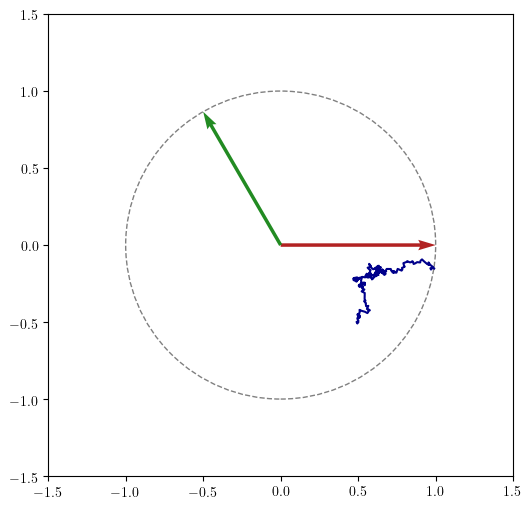

In [544]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(X[:, 0], X[:, 1], label='Trajectory', color='darkblue')
# ax.plot(X[0, 0], X[0, 1], 'ro', label='Start', markersize=8)
# for seg in X:  # traj_full could also be a list of segments if you kept them separate
#     ax.plot(seg[:, 0], seg[:, 1], color='darkblue')
#mark where control kicks in
t_start_idx = int(t_start/dt)
print(t_start_idx)
#ax.plot(X[t_start_idx, 0], X[t_start_idx, 1], 'go', label='Control Start', markersize=8)
# draw circle bound
circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--')


#plot stable and unstable direction of dynamics
ax.quiver(0, 0, Q_mat[0,0], Q_mat[1,0], angles='xy', scale_units='xy', scale=1, color='firebrick', label='Unstable Direction')
ax.quiver(0, 0, Q_mat[0,1], Q_mat[1,1], angles='xy', scale_units='xy', scale=1, color='forestgreen', label='Stable Direction')
ax.add_artist(circle)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)  ;

### Location estimation

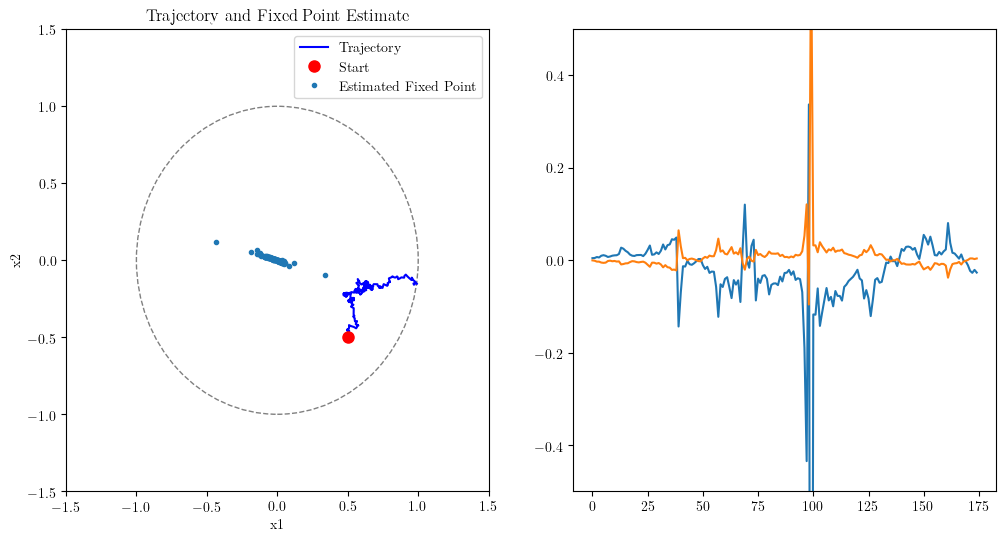

In [515]:
def sliding_window_fp(X, window_size=50):
    """
    Estimate A_t and b_t in a sliding window over trajectory X.
    
    X: (T, d) trajectory
    window_size: number of steps in the sliding window
    
    Returns:
        A_list: list of estimated A matrices
        b_list: list of estimated b vectors
    """
    T, d = X.shape
    A_list = []
    b_list = []

    for t0 in range(T - window_size):
        X_p = X[t0 : t0 + window_size - 1].T  # past states (d, W-1)
        X_f = X[t0 + 1 : t0 + window_size].T  # future states (d, W-1)

        # Estimate A
        A = X_f @ X_p.T @ np.linalg.pinv(X_p @ X_p.T)

        # Estimate b (fixed point)
        dX = X_f - A @ X_p
        mean_dX = np.mean(dX, axis=1)
        I = np.eye(d)
        b = np.linalg.pinv(I - A) @ mean_dX

        A_list.append(A)
        b_list.append(b)

    return np.array(A_list), np.array(b_list)

# Example usage
window_size = 50
A_list, b_list = sliding_window_fp(X, window_size=window_size)

fig, (ax1, ax2) = plt.subplots(figsize=(12, 6), nrows=1, ncols=2)
ax1.plot(X[:, 0], X[:, 1], label='Trajectory', color='blue')

# Start point
ax1.plot(X[0, 0], X[0, 1], 'ro', label='Start', markersize=8)

# Sliding window fixed point (b_list)
# align indices with trajectory
fp_indices = np.arange(window_size, len(X))
ax1.plot(b_list[:, 0], b_list[:, 1], '.', label='Estimated Fixed Point', linewidth=2)

# draw circle bound
circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--')
ax1.add_artist(circle)

ax1.set_xlim(-1.5, 1.5)
ax1.set_ylim(-1.5, 1.5)
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.set_title("Trajectory and Fixed Point Estimate")
ax1.legend()

ax2.plot(b_list[:, 0], label='b_x')
ax2.plot(b_list[:, 1], label='b_y')
ax2.set_ylim(-.5, .5)
plt.show()


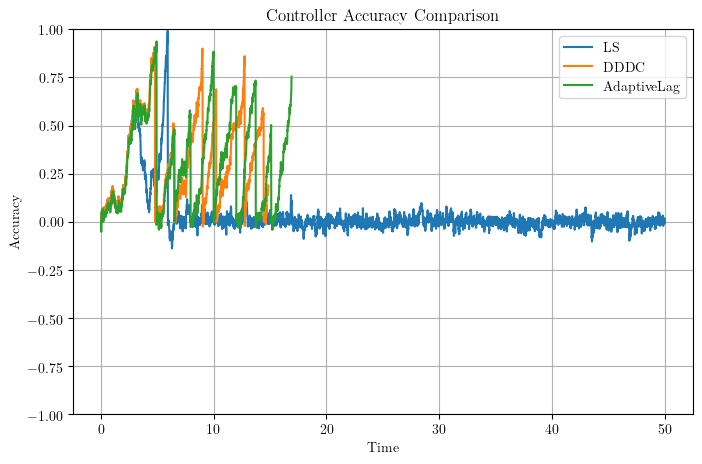

In [558]:

results = {}
# --- Accuracy function ---
def accuracy(traj, target=np.zeros(2)):
    """Accuracy as distance from target"""
    return np.linalg.norm(traj - target, axis=1)

def accuracy(traj, target_vector=np.array([1.0, 1.0])):
    """Compute the accuracy score as the distance from the target subspace."""
    return np.dot(traj, target_vector)

# 
x0 = np.array([.7, -.7])
bound = 1.0
t_span = [0.0, 50.0]
dt = 0.01
control_vector = [1.0, 1.0] / np.sqrt(2)  # normalized control vector
noise_std = 0.1
t_start = 3.0
control_noise_std = 0.01

# --- Initialize controllers ---
controllers = {
    "LS": LS_Controller(control_vector, t_start=t_start, control_noise_std=0, window=300, u_max=.4),
    "DDDC": DDDC_Controller(control_vector, t_start=t_start, control_noise_std=control_noise_std),
    "AdaptiveLag": AdaptiveLagController(m=2, k=2, l_u=1, l_y=20, C=np.eye(2), t_start=t_start),
   # "DualDescent": DualDescentController(state_covariance=np.eye(2), control_covariance=np.eye(2), t_start=t_start, control_noise_std=control_noise_std)
}

# --- Run simulations ---
results = {}
for name, ctrl in controllers.items():
    times, traj, ctrls = simulate_euler_maruyama_control_restart(drift, ctrl, x0, t_span, dt, noise_std, bound=bound, rs=1)
    traj = np.concatenate(traj)  # ensure it's a single array
    acc = accuracy(traj)
    results[name] = (times, traj, ctrls, acc)

# ------------------------------
# Plot accuracy
# ------------------------------
plt.figure(figsize=(8,5))
for name, (times, traj, ctrls, acc) in results.items():
    times = np.concatenate(times)  # ensure times are concatenated
    plt.plot(times, acc, label=name)
plt.ylim(-1, 1)
plt.xlabel("Time")
plt.ylabel("Accuracy")
plt.title("Controller Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.show()

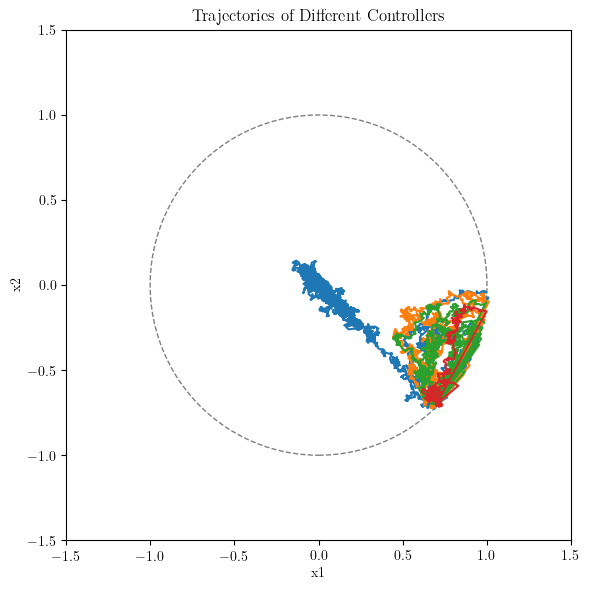

In [531]:
# ------------------------------
# Plot all trajectories in one figure
# ------------------------------
fig, ax = plt.subplots(figsize=(6, 6))

for name, (times, traj, ctrls, acc) in results.items():
    ax.plot(traj[:, 0], traj[:, 1], label=f'{name} Trajectory')
    # for seg in traj:  # traj could also be a list of segments if you kept them separate
    #     ax.plot(seg[:, 0], seg[:, 1], color=ax.get_lines()[-1].get_color(), alpha=0.3)

    # start point
#     ax.plot(traj[0, 0], traj[0, 1], 'o', color=ax.get_lines()[-1].get_color(),
#             markersize=6, label=f"{name} Start")

    # mark where control kicks in
#     t_start_idx = np.searchsorted(times, t_start)
#     ax.plot(traj[t_start_idx, 0], traj[t_start_idx, 1],
#             'x', color=ax.get_lines()[-1].get_color(),
#             markersize=8, label=f"{name} Control Start")

    # print(f"{name}: control starts at index {t_start_idx}, time {times[t_start_idx]:.2f}")

# draw circle bound
circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--')
ax.add_artist(circle)

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Trajectories of Different Controllers")
#ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [12]:
def estimate_projection_dynamics(trajectories: list[np.ndarray], w_l: np.ndarray) -> tuple[float, float]:
    """
    Estimate scalar a_l and projected noise variance sigma^2 along w_l:
        <w_l, x_{t+1}> ≈ a_l * <w_l, x_t> + noise

    Parameters:
        trajectories: list of arrays (T_i, d)
        w_l: direction vector (d,) — need not be normalized

    Returns:
        a_l: scalar estimate of linear dynamics along w_l
        sigma2: estimated noise variance along w_l
    """
    proj_x = []
    proj_y = []

    for traj in trajectories:
        if traj.shape[0] < 2:
            continue
        x_t = traj[:-1]     # (T-1, d)
        x_tp1 = traj[1:]    # (T-1, d)
        proj_x.append(x_t @ w_l)   # project to scalar
        proj_y.append(x_tp1 @ w_l)

    x_proj = np.concatenate(proj_x)  # (N,)
    y_proj = np.concatenate(proj_y)  # (N,)

    # Least squares in 1D: y = a x + ε
    numerator = np.dot(x_proj, y_proj)
    denominator = np.dot(x_proj, x_proj)
    a_l = numerator / denominator

    residuals = y_proj - a_l * x_proj
    sigma2 = np.mean(residuals**2)

    return a_l, np.sqrt(sigma2)

def estimate_projection_dynamics_cont(trajectories: list[np.ndarray], w_l: np.ndarray, dt: float) -> tuple[float, float]:
    """
    Estimate scalar a_l and projected noise variance sigma^2 along w_l:
        <w_l, x_{t+1}> ≈ a_l * <w_l, x_t> + noise

    Parameters:
        trajectories: list of arrays (T_i, d)
        w_l: direction vector (d,) — need not be normalized

    Returns:
        a_l: scalar estimate of linear dynamics along w_l
        sigma2: estimated noise variance along w_l
    """
    a_l, sigma = estimate_projection_dynamics(trajectories, w_l)
    return np.log(a_l) / dt, sigma / np.sqrt(dt)

def estimate_A_and_noise_cov(trajectories: list[np.ndarray]):
    """
    Estimate matrix A and noise covariance Sigma in
    x_{t+1} = A x_t + noise.

    Parameters:
        trajectories: list of arrays (T_i, d).

    Returns:
        A: (d, d) matrix estimate.
        Sigma: (d, d) covariance estimate of noise.
    """
    X_list = []
    Y_list = []

    for traj in trajectories:
        if traj.shape[0] < 2:
            continue
        x_t = traj[:-1]
        x_tp1 = traj[1:]
        X_list.append(x_t)
        Y_list.append(x_tp1)

    X = np.vstack(X_list)  # (N, d)
    Y = np.vstack(Y_list)  # (N, d)

    X_T = X.T  # (d, N)
    Y_T = Y.T  # (d, N)

    A = Y_T @ X_T.T @ np.linalg.pinv(X_T @ X_T.T)

    residuals = Y - (X @ A.T)  # (N, d)
    Sigma = np.cov(residuals, rowvar=False, bias=True)  # (d, d)

    if residuals.shape[0] < 2:
        Sigma = np.zeros((residuals.shape[1], residuals.shape[1]))
    else:
        Sigma = np.cov(residuals, rowvar=False, bias=True)

    return A, Sigma

def discrete_to_continuous_noise_cov(M: np.ndarray, Sigma: np.ndarray, delta_t: float) -> np.ndarray:
    """
    Convert discrete-time noise covariance Sigma to continuous-time noise covariance Q
    for the system dx = M x dt + B dW, with discrete dynamics A = expm(M delta_t).
    
    Parameters:
        M: Continuous-time system matrix (d x d).
        Sigma: Discrete-time noise covariance matrix (d x d).
        delta_t: Sampling timestep.
        
    Returns:
        Q: Continuous-time noise covariance matrix (d x d).
    """
    d = M.shape[0]
    K = kron(M, np.eye(d)) + kron(np.eye(d), M)  # (d^2 x d^2)
    exp_Kdt = expm(K * delta_t)
    
    # Compute the integral operator matrix
    integral_op = inv(K) @ (exp_Kdt - np.eye(d * d))
    
    vec_Sigma = Sigma.flatten()
    eps = 1e-10
    integral_op_reg = integral_op + eps * np.eye(integral_op.shape[0])
    vec_Q = np.linalg.solve(integral_op_reg, vec_Sigma)
    Q = vec_Q.reshape(d, d)
    return Q


def discrete_to_continuous_noise_cov(A_d, Sigma_d, dt):
    """
    Convert discrete-time dynamics A_d and noise covariance Sigma_d
    to continuous-time noise covariance Q using Lyapunov equation.

    Parameters:
        A_d: discrete-time dynamics matrix (d, d)
        Sigma_d: discrete-time noise covariance matrix (d, d)
        dt: time step

    Returns:
        Q: continuous-time noise covariance matrix (d, d)
    """
    # Compute continuous-time dynamics matrix A_c
    A_c = logm(A_d) / dt

    # Solve continuous Lyapunov equation: A_c Sigma_d + Sigma_d A_c^T + Q = 0
    # Rearranged: A_c Sigma_d + Sigma_d A_c^T = -Q
    Q = -solve_continuous_lyapunov(A_c, Sigma_d)

    return Q

def estimate_A_and_noise_cov_cont(trajectories: list[np.ndarray], dt: float) -> tuple[np.ndarray, np.ndarray]:
    """
    Estimate continuous-time matrix A and noise covariance Sigma in
    dx = A x dt + B dW.

    Parameters:
        trajectories: list of arrays (T_i, d).
        dt: time step.

    Returns:
        A: (d, d) matrix estimate.
        Sigma: (d, d) covariance estimate of noise.
    """
    A_d, Sigma_d = estimate_A_and_noise_cov(trajectories)
    Q = discrete_to_continuous_noise_cov(A_d, Sigma_d, dt)
    return Q, Sigma_d



array([[ 0.5,  0. ],
       [ 0. , -0.5]])

### Comparing least-squares estimates of unstable $\lambda$
Which part of trajectories:
1. Full trajectories in beighborhood
1. Entries 

Which part of state space
1. Full state space
1. Projected state space (onto left stable eigenvector)

In [23]:
import pandas as pd

results = []

for i in tqdm(range(N_sims), desc="Simulating trajectories"):
    x0s = generate_initial_conditions(
        n_traj, 1.0,
        circle=circle_init,
        along_stable=along_stable,
        angle_range=angle_range,
        angle_distribution=angle_distribution
    )

    sim_result = {
        "sim_id": i,
        "trajs": [],
        "lambda_us_proj": [],
        "sigmas_proj": [],
        "lambda_us_full": [],
        "sigmas_full": [],
        "lambda_us_proj_entries": [],
        "sigmas_proj_entries": [],
        "lambda_us_full_entries": [],
        "sigmas_full_entries": [],
        "lambda_us_running_proj": [],
        "lambda_us_running_full": [],
    }

    lambda_running_proj = None
    lambda_running_full = None

    for x0 in x0s:
        # t_vals, traj = simulate_euler_maruyama(
        #     lambda x, t: A @ x, x0=x0, t_span=t_span, dt=dt,
        #     noise_std=0.1, circle=True
        # )
        t_vals, traj, controls = simulate_euler_maruyama_control(
            drift_func=lambda x: A @ x, 
            control_func=lambda t, x, **kwargs: np.zeros_like(x),  # no control
            x0=x0,
            t_span=t_span,
            dt=dt,
            noise_std=0.1,
            circle=True
        )
        sim_result["trajs"].append(traj)

        # --- projection estimation ---
        a_l_proj, sigma_proj = estimate_projection_dynamics_cont([traj], left_stable_eigenvector, dt)
        sim_result["lambda_us_proj"].append(a_l_proj)
        sim_result["sigmas_proj"].append(sigma_proj)

        # --- full dynamics estimation ---
        a_l_full, sigma_full = estimate_A_and_noise_cov([traj])
        Q = discrete_to_continuous_noise_cov(a_l_full, sigma_full, dt)
        eigenvalues_full, _ = np.linalg.eig(a_l_full)
        sim_result["lambda_us_full"].append(np.log(eigenvalues_full[0]) / dt)
        sim_result["sigmas_full"].append(np.sqrt(np.mean(sigma_full)) / np.sqrt(dt))

        # --- running estimates ---
        if lambda_running_proj is None:
            lambda_running_proj = a_l_proj
        else:
            lambda_running_proj = lambda_running_gamma * a_l_proj + (1 - lambda_running_gamma) * lambda_running_proj

        if lambda_running_full is None:
            eigenvalues_full, _ = np.linalg.eig(a_l_full)
            lambda_running_full = np.max(np.real(eigenvalues_full))
        else:
            eigenvalues_full, _ = np.linalg.eig(a_l_full)
            max_eigenvalue = np.max(np.real(eigenvalues_full))
            lambda_running_full = lambda_running_gamma * np.log(max_eigenvalue) / dt + (1 - lambda_running_gamma) * lambda_running_full

        sim_result["lambda_us_running_proj"].append(lambda_running_proj)
        sim_result["lambda_us_running_full"].append(lambda_running_full)

    results.append(sim_result)

# Convert to DataFrame if you want tabular access (lists will still be there)
df_results = pd.DataFrame(results)


Simulating trajectories:   0%|          | 0/100 [00:00<?, ?it/s]


TypeError: <lambda>() takes 1 positional argument but 2 were given

In [6]:
rs = 42
np.random.seed(rs)
N_sims = 100
n_traj = 100+3
t_span=(0, 50)
dt = 0.01

lambda_running_gamma = 0.1

all_trajs = []
all_lambda_us_proj = []
all_sigmas_proj = []
all_lambda_us_full = []
all_sigmas_full = []
all_lambda_us_proj_entries = []
all_sigmas_proj_entries = []
all_lambda_us_full_entries = []
all_sigmas_full_entries = []
all_lambda_us_running_proj = []
all_lambda_us_running_full = []
all_lambda_us_running_proj_entries = []
all_lambda_us_running_full_entries = []
init_method = 'ring_unstable_normal'

if init_method == 'ring_unstable_normal':
    circle_init = True
    angle_distribution = 'normal'
    along_stable = Q_mat[:, 1]

elif init_method == 'ring_unstable_uniform':
    circle_init = True
    angle_distribution = 'uniform'
    along_stable = Q_mat[:, 1]
elif init_method == 'ring_uniform':
    circle_init = True
    angle_distribution = 'uniform'
    along_stable = None
elif init_method == 'uniform':
    circle_init = False
angle_range = np.pi / 32

# left_stable_eigenvector = orthogonal to the stable eigenvector
left_stable_eigenvector = np.array([-Q_mat[1, 1], Q_mat[0, 1]])
for i in tqdm(range(N_sims), desc="Simulating trajectories"):
    x0s = generate_initial_conditions(n_traj, 1.0, circle=circle_init, along_stable=along_stable, angle_range=angle_range, angle_distribution=angle_distribution)
    trajs = []
    lambda_us_proj = []
    sigmas_proj = []
    lambda_us_full = []
    sigmas_full = []
    lambda_us_proj_entries = []
    sigmas_proj_entries = []
    lambda_us_full_entries = []
    sigmas_full_entries = []
    lambdas_running = [] # for all methods
    lambdas_running_proj = []
    lambdas_running_full = []
    lambdas_running_proj_entries = []
    lambdas_running_full_entries = []

    lambda_running_proj = None
    lambda_running_full = None
    lambda_running_proj_entries = None
    lambda_running_full_entries = None
    for x0 in x0s:
        t_vals, traj = simulate_euler_maruyama(lambda x: A @ x, x0=x0, t_span=t_span, dt=dt, noise_std=0.1, circle=True)
        trajs.append(traj)
        # estimate along first eigenvector
        a_l_proj, sigma_proj = estimate_projection_dynamics_cont(trajs, left_stable_eigenvector, dt)  
        lambda_us_proj.append(a_l_proj)
        sigmas_proj.append(sigma_proj)  

        # estimate full dynamics
        a_l_full, sigma_full = estimate_A_and_noise_cov(trajs)
        Q = discrete_to_continuous_noise_cov(a_l_full, sigma_full, dt)
        eigenvalues_full, Q_mat_full = np.linalg.eig(a_l_full)
        lambda_us_full.append(np.log(eigenvalues_full[0])/dt)
        sigmas_full.append(np.sqrt(np.mean(sigma_full)) / np.sqrt(dt))

        #estimate from entries
        trajs_entries = [traj[0:2,:] for traj in trajs]
        a_l_proj_entries, sigma_proj_entries = estimate_projection_dynamics_cont(trajs_entries, left_stable_eigenvector, dt)
        lambda_us_proj_entries.append(a_l_proj_entries)
        sigmas_proj_entries.append(sigma_proj_entries)

        #full dynamics from entries
        a_l_full_entries, sigma_full_entries = estimate_A_and_noise_cov(trajs_entries)
        eigenvalues_full_entries, Q_mat_full_entries = np.linalg.eig(a_l_full_entries)
        max_eigenvalue = np.max(np.real(eigenvalues_full_entries))
        lambda_us_full_entries.append(np.real(np.log(max_eigenvalue)/dt))
        sigmas_full_entries.append(np.sqrt(np.mean(sigma_full_entries)) / np.sqrt(dt))

        # dddc
        # w_star = direct_data_driven_control(trajs, controls, w_l)

        # running estimates
        if len(trajs) == 1:
            lambda_running_proj, _ = estimate_projection_dynamics_cont(trajs, left_stable_eigenvector, dt)
        else: 
            a_l_proj, sigma_proj = estimate_projection_dynamics_cont([trajs[-1]], left_stable_eigenvector, dt)
            lambda_running_proj = lambda_running_gamma * a_l_proj + (1 - lambda_running_gamma) * lambda_running_proj

        if len(trajs) == 1:
            a_l_full, _ = estimate_A_and_noise_cov_cont(trajs, dt)
            eigenvalues_full, Q_mat_full = np.linalg.eig(a_l_full)
            lambda_running_full = eigenvalues_full[0]
        else:
            a_l_full, sigma_full = estimate_A_and_noise_cov_cont([trajs[-1]], dt)
            a_l_full, sigma_full = estimate_A_and_noise_cov([trajs[-1]])
            eigenvalues_full, Q_mat_full = np.linalg.eig(a_l_full)
            max_eigenvalue = np.max(np.real(eigenvalues_full))
            #print(f"max_eigenvalue: {np.log(max_eigenvalue)/dt}")
            lambda_running_full = lambda_running_gamma * np.log(max_eigenvalue)/dt + (1 - lambda_running_gamma) * lambda_running_full

        lambdas_running_proj.append(lambda_running_proj)
        lambdas_running_full.append(lambda_running_full)

    all_trajs.append(trajs)
    all_lambda_us_proj.append(np.array(lambda_us_proj))
    all_sigmas_proj.append(np.array(sigmas_proj))
    all_lambda_us_full.append(np.array(lambda_us_full))
    all_sigmas_full.append(np.array(sigmas_full))
    all_lambda_us_proj_entries.append(np.array(lambda_us_proj_entries))
    all_sigmas_proj_entries.append(np.array(sigmas_proj_entries))
    all_lambda_us_full_entries.append(np.array(lambda_us_full_entries))
    all_sigmas_full_entries.append(np.array(sigmas_full_entries))
    all_lambda_us_running_proj.append(lambdas_running_proj)
    all_lambda_us_running_full.append(lambdas_running_full)

Simulating trajectories:   0%|          | 0/100 [00:00<?, ?it/s]c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\scipy\linalg\_matfuncs.py:204: LogmExactlySingularWarning: The logm input matrix is exactly singular.
  F = scipy.linalg._matfuncs_inv_ssq._logm(A)
Simulating trajectories:   1%|          | 1/100 [00:01<03:12,  1.95s/it]C:\Users\abel_\AppData\Local\Temp\ipykernel_21568\1985520308.py:52: RuntimeWarning: invalid value encountered in log
  return np.log(a_l) / dt, sigma / np.sqrt(dt)
Simulating trajectories:   3%|▎         | 3/100 [00:05<03:24,  2.10s/it]C:\Users\abel_\AppData\Local\Temp\ipykernel_21568\877576383.py:77: RuntimeWarning: invalid value encountered in log
  lambda_us_full.append(np.log(eigenvalues_full[0])/dt)
Simulating trajectories:   6%|▌         | 6/100 [00:14<04:18,  2.75s/it]C:\Users\abel_\AppData\Local\Temp\ipykernel_21568\877576383.py:77: RuntimeWarning: divide by zero encountered in log
  lambda_us_full.append(np.log(eigenvalues_full[0])/dt)
Simulating

c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\numpy\ma\core.py:2820: ComplexWarning: Casting complex values to real discards the imaginary part
  _data = np.array(data, dtype=dtype, copy=copy,
c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\matplotlib\axes\_axes.py:7132: ComplexWarning: Casting complex values to real discards the imaginary part
  bins = np.array(bins, float)  # causes problems if float16
c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\abel_\AppData\Local\Tem

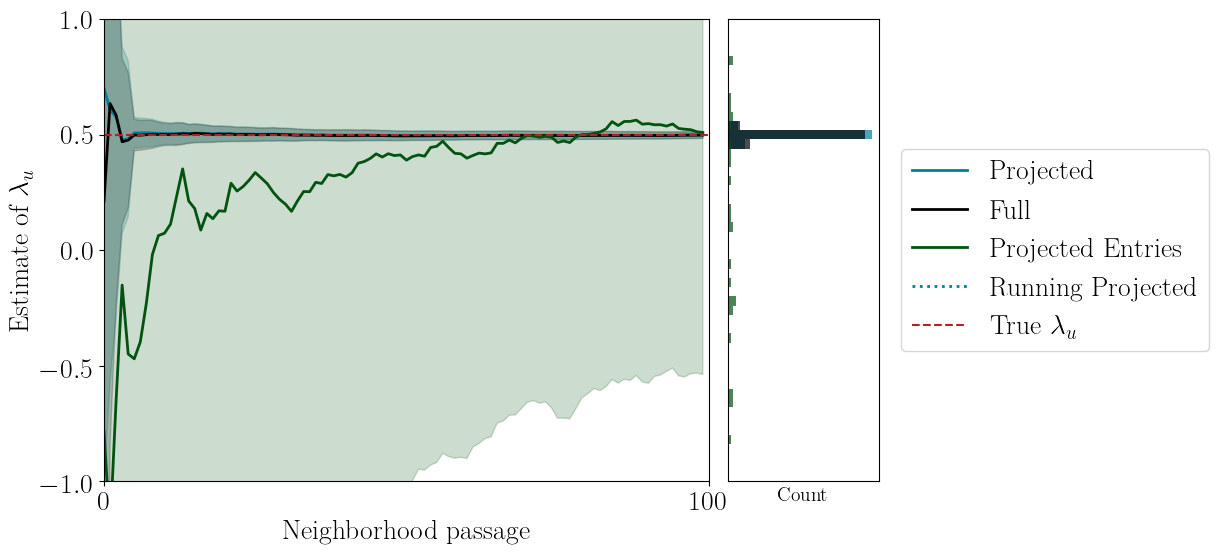

In [7]:
# Convert list of arrays to (n_sim, T) array for stats
lambda_proj = np.array([l[2:] for l in all_lambda_us_proj])  # shape (n_sim, T)
mean_lambda_proj = lambda_proj.mean(axis=0)
std_lambda_proj = lambda_proj.std(axis=0)

lambda_full = np.array([l[2:] for l in all_lambda_us_full])  # shape (n_sim, T)
mean_lambda_full = lambda_full.mean(axis=0)
std_lambda_full = lambda_full.std(axis=0)

lambda_proj_entries = np.array([l[2:] for l in all_lambda_us_proj_entries])  # shape (n_sim, T)
mean_lambda_proj_entries = lambda_proj_entries.mean(axis=0)
std_lambda_proj_entries = lambda_proj_entries.std(axis=0)

lambda_us_full_entries = np.array([l[2:] for l in all_lambda_us_full_entries])  # shape (n_sim, T)
mean_lambda_full_entries = lambda_us_full_entries.mean(axis=0)
std_lambda_full_entries = lambda_us_full_entries.std(axis=0)

lambda_running_proj = np.array([l[2:] for l in all_lambda_us_running_proj])  # shape (n_sim, T)
mean_lambda_running_proj = lambda_running_proj.mean(axis=0)
std_lamda_running_proj = lambda_running_proj.std(axis=0)

lambda_running_full = np.array([l[2:] for l in all_lambda_us_running_full])  # shape (n_sim, T)
mean_lambda_running_full = lambda_running_full.mean(axis=0)
std_lambda_running_full = lambda_running_full.std(axis=0)


# Final values for histogram
final_lambda_us_proj = lambda_proj[:, -1]
final_lambda_us_full = lambda_full[:, -1]
final_lambda_us_proj_entries = lambda_proj_entries[:, -1]
final_lambda_us_full_entries = lambda_us_full_entries[:, -1]
final_lambda_running_proj = lambda_running_proj[:, -1]

# Set up grid layout
fig = plt.figure(figsize=(10, 6))
gs = GridSpec(1, 2, width_ratios=[4, 1], wspace=0.05)

# Main plot
ax = fig.add_subplot(gs[0])
# for lambda_us in all_lambda_us_proj:
#     ax.plot(lambda_us[2:], color=ccn_color, alpha=0.4)

# Mean ± std
t_vals = np.arange(lambda_proj.shape[1])
ax.plot(t_vals, mean_lambda_proj, color=ccn_color, linewidth=2, label='Projected')
ax.fill_between(t_vals, mean_lambda_proj - std_lambda_proj, mean_lambda_proj + std_lambda_proj,
                color=ccn_color, alpha=0.2, label='')

ax.plot(t_vals, mean_lambda_full, color='k', linewidth=2, label='Full')
ax.fill_between(t_vals, mean_lambda_full - std_lambda_full, mean_lambda_full + std_lambda_full,
                color='k', alpha=0.2, label='')

ax.plot(t_vals, mean_lambda_proj_entries, color=committor_region_color, linewidth=2, label='Projected Entries')
ax.fill_between(t_vals, mean_lambda_proj_entries - std_lambda_proj_entries, mean_lambda_proj_entries + std_lambda_proj_entries,
                color=committor_region_color, alpha=0.2, label='')

# ax.plot(t_vals, mean_lambda_full_entries, color='purple', linewidth=2, label='Full Entries')
# ax.fill_between(t_vals, mean_lambda_full_entries - std_lambda_full_entries, mean_lambda_full_entries + std_lambda_full_entries,
#                 color='purple', alpha=0.2, label='')

ax.plot(t_vals, mean_lambda_running_proj, color=ccn_color, linestyle=':', linewidth=2, label='Running Projected')
ax.fill_between(t_vals, mean_lambda_running_proj - std_lamda_running_proj, mean_lambda_running_proj + std_lamda_running_proj,
                color=ccn_color, alpha=0.2, label='')

# ax.plot(t_vals, mean_lambda_running_full, color='k', linestyle=':', linewidth=2, label='Running Full')
# ax.fill_between(t_vals, mean_lambda_running_full - std_lambda_running_full, mean_lambda_running_full + std_lambda_running_full,
#                 color='k', alpha=0.2, label='')

# Separatrix line
ax.axhline(y=0.5, color=separatrix_color, linestyle='--', label='True $\lambda_u$')

#ax.set_xlabel(r"nth trajectory through neighborhood", fontsize=20)
ax.set_xlabel("Neighborhood passage", fontsize=20)
ax.set_ylabel(r"Estimate of $\lambda_u$", fontsize=20)
# ax.xaxis.set_major_locator(MaxNLocator(integer=True))
# ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(0, n_traj - 3)
ax.set_ylim(-1, 1)
ax.legend(loc='center right', bbox_to_anchor=(1.85, 0.5), fontsize=20)
ax.set_xticks([0, n_traj - 3])
ax.set_xticklabels([0, N_sims], fontsize=20)
ax.set_yticks([0, 0.5, 1])
ax.set_yticks([-1,-.5,0, 0.5, 1])
ax.tick_params(axis='both', which='major', labelsize=20)

# Side histogram
ax_hist = fig.add_subplot(gs[1], sharey=ax)
all_data = np.concatenate([final_lambda_us_proj, final_lambda_us_full, final_lambda_us_proj_entries])
bin_edges = np.histogram_bin_edges(all_data, bins=50, range=(-1, 1))  # Use a fixed range for all histograms
# Use the same bin edges for all histograms
ax_hist.hist(final_lambda_us_proj, bins=bin_edges, orientation='horizontal', color=ccn_color, alpha=0.7)
ax_hist.hist(final_lambda_us_full, bins=bin_edges, orientation='horizontal', color='k', alpha=0.7, label='Full')
ax_hist.hist(final_lambda_us_proj_entries, bins=bin_edges, orientation='horizontal', color=committor_region_color, alpha=0.7, label='Projected Entries')
ax_hist.hist(final_lambda_running_proj, bins=bin_edges, orientation='horizontal', color='darkblue', alpha=0.7, label='Running Projected')
#ax_hist.hist(final_lambda_us_full_entries, bins=bin_edges, orientation='horizontal', color='purple', alpha=0.7, label='Full Entries')
ax_hist.set_xlabel("Count", fontsize=14)
ax_hist.yaxis.set_visible(False)
#ax_hist.xaxis.set_major_locator(MaxNLocator(integer=True))
ax_hist.set_xticks([])
plt.tight_layout()
if circle_init and along_stable is not None:
    plt.savefig(f"figures/lambda_estimates_unctrl_{init_method}_rangepiover{np.pi/angle_range:.0f}.pdf", dpi=300, bbox_inches='tight')
else:
    plt.savefig(f"figures/lambda_estimates_unctrl_{init_method}.pdf", dpi=300, bbox_inches='tight')

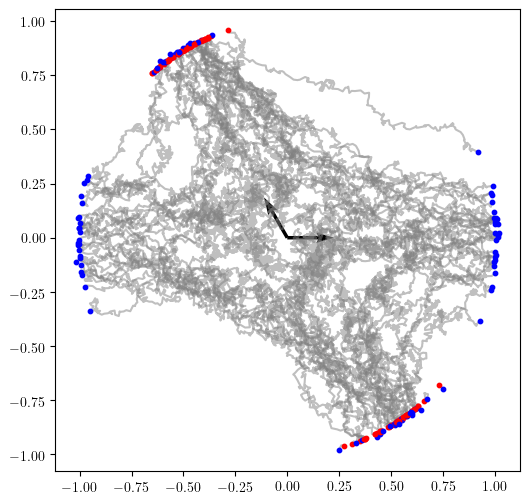

In [28]:
fig, ax = plt.subplots(figsize=(6, 6))
for traj in trajs:
    ax.plot(traj[:, 0], traj[:, 1], color='gray', alpha=0.5)
    ax.scatter(traj[0, 0], traj[0, 1], color='red', s=10, label='Initial condition', zorder=5)
    ax.scatter(traj[-1, 0], traj[-1, 1], color='blue', s=10, label='Final condition', zorder=5)
ax.quiver(0, 0, Q_mat[0, 0], Q_mat[1, 0], color='black', scale=10, label=r"$\mathbf{q}_1$")
ax.quiver(0, 0, Q_mat[0, 1], Q_mat[1, 1], color='black', scale=10, label=r"$\mathbf{q}_2$")

In [ ]:
# improve code
rs = 42
np.random.seed(rs)
N_sims = 100
n_traj = 103  # 100+3
t_span = (0, 50)
dt = 0.01

from tqdm import tqdm
from typing import Tuple
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


def run_multiple_simulations(
    N_sims: int,
    n_traj: int,
    t_span: Tuple[float, float],
    dt: float,
    A: np.ndarray,
    Q_mat: np.ndarray,
    noise_std: float = 0.1,
    angle_range: float = np.pi / 32,
    seed: int = 42
) -> dict:
    """
    Run multiple stochastic simulations and estimate dominant eigenvalues and noise.

    Parameters:
        N_sims: number of simulations
        n_traj: number of trajectories per simulation
        t_span: time span for simulation
        dt: time step
        A: system matrix
        Q_mat: matrix of eigenvectors (columns)
        noise_std: noise strength for Euler-Maruyama
        angle_range: range for initial condition spread
        seed: random seed

    Returns:
        A dictionary containing:
            - lambda_us (dict with keys: proj, full, proj_entries, full_entries)
            - sigmas (same keys)
            - trajs: full trajectory sets for each simulation
    """
    np.random.seed(seed)
    
    results = {
        'lambda_us': {k: [] for k in ['proj', 'full', 'proj_entries', 'full_entries']},
        'sigmas':    {k: [] for k in ['proj', 'full', 'proj_entries', 'full_entries']},
        'trajs': []
    }

    for _ in tqdm(range(N_sims), desc="Simulating trajectories"):
        x0s = generate_initial_conditions(
            n_traj, 1.0, circle=True,
            along_stable=Q_mat[:, 1],
            angle_range=angle_range,
            angle_distribution='normal'
        )

        trajs = [
            simulate_euler_maruyama(
                lambda x: A @ x, x0=x0, t_span=t_span,
                dt=dt, noise_std=noise_std, circle=True
            )[1]
            for x0 in x0s
        ]
        
        #trajs = np.stack(trajs)  # shape: (n_traj, dim, T)
        trajs_entries = np.array([traj[0:2,:] for traj in trajs])  # shape: (n_traj, 2, T)

        # --- Projected dynamics ---
        a_l_proj, sigma_proj = estimate_projection_dynamics(trajs, Q_mat[:, 0])
        lambda_proj = np.log(a_l_proj) / dt
        sigma_proj = sigma_proj / np.sqrt(dt)

        # --- Full dynamics ---
        a_l_full, sigma_full = estimate_A_and_noise_cov(trajs)
        eigenvalues_full, _ = np.linalg.eig(a_l_full)
        lambda_full = np.log(eigenvalues_full[0]) / dt
        sigma_full = np.sqrt(np.mean(sigma_full)) / np.sqrt(dt)

        # --- Projected entries only ---
        a_l_proj_entries, sigma_proj_entries = estimate_projection_dynamics(trajs_entries, Q_mat[:, 0])
        lambda_proj_entries = np.log(a_l_proj_entries) / dt
        print(f"lambda_proj_entries: {lambda_proj_entries}")
        sigma_proj_entries = sigma_proj_entries / np.sqrt(dt)

        # --- Full from entries ---
        a_l_full_entries, sigma_full_entries = estimate_A_and_noise_cov(trajs_entries)
        eigenvalues_full_entries, _ = np.linalg.eig(a_l_full_entries)
        lambda_full_entries = np.log(eigenvalues_full_entries[0]) / dt
        sigma_full_entries = np.sqrt(np.mean(sigma_full_entries)) / np.sqrt(dt)

        # --- Store all ---
        results['trajs'].append(trajs)
        results['lambda_us']['proj'].append(lambda_proj)
        results['lambda_us']['full'].append(lambda_full)
        results['lambda_us']['proj_entries'].append(lambda_proj_entries)
        results['lambda_us']['full_entries'].append(lambda_full_entries)
        
        results['sigmas']['proj'].append(sigma_proj)
        results['sigmas']['full'].append(sigma_full)
        results['sigmas']['proj_entries'].append(sigma_proj_entries)
        results['sigmas']['full_entries'].append(sigma_full_entries)

    return results

# results = run_multiple_simulations(N_sims=100, n_traj=103,    t_span=(0, 50),    dt=0.01,    A=A,    Q_mat=Q_mat)

def plot_lambda_estimates(results: dict, ccn_color='blue', separatrix_color='red', bins=50):
    """
    Plot λ_u estimates over trajectories and final value histograms from simulation results.
    
    Parameters:
        results: Dictionary returned by run_multiple_simulations.
        ccn_color: Color for the 'Projected' method.
        separatrix_color: Color of the reference horizontal line.
        bins: Number of bins for histograms.
    """
    # Strip first two timepoints (assumed unreliable) and convert to arrays
    lambda_types = ['proj', 'full', 'proj_entries']
    lambdas = {}
    for key in lambda_types:
        values = results['lambda_us'].get(key, [])
        cleaned = []
        for l in values:
            # Convert to np.array if not already
            arr = np.array(l)
            # Only slice if array is at least 1D
            if arr.ndim >= 1 and arr.shape[0] > 2:
                cleaned.append(arr[2:])
            else:
                warnings.warn(f"Skipping non-sliceable entry in '{key}': shape={arr.shape}, type={type(l)}")
        lambdas[key] = np.array(cleaned)


    means = {k: v.mean(axis=0) for k, v in lambdas.items()}
    stds = {k: v.std(axis=0) for k, v in lambdas.items()}

    final_vals = {}
    for k, v in lambdas.items():
        if v.ndim == 2:
            final_vals[k] = v[:, -1]  # last element along time axis
        elif v.ndim == 1:
            final_vals[k] = v  # already 1D, no trailing index
        else:
            raise ValueError(f"Unexpected shape for lambdas[{k}]: {v.shape}")


    # Set up figure and gridspec
    fig = plt.figure(figsize=(10, 6))
    gs = GridSpec(1, 2, width_ratios=[4, 1], wspace=0.05)

    ax = fig.add_subplot(gs[0])
    if lambdas['proj'].ndim == 2:
        t_vals = np.arange(lambdas['proj'].shape[1])
    elif lambdas['proj'].ndim == 1:
        t_vals = np.arange(lambdas['proj'].shape[0])  # fallback, one timepoint per sim
    else:
        raise ValueError(f"Unexpected lambdas['proj'] shape: {lambdas['proj'].shape}")


    # Plot each method
    if lambdas['proj'].ndim == 2 and lambdas['proj'].shape[1] > 0:
        t_vals = np.arange(lambdas['proj'].shape[1])
    elif lambdas['proj'].ndim == 1 and lambdas['proj'].shape[0] > 0:
        t_vals = np.arange(lambdas['proj'].shape[0])
    else:
        # fallback: t_vals is same length as means['proj'] or 1
        t_len = len(means['proj']) if hasattr(means['proj'], '__len__') else 1
        t_vals = np.arange(max(t_len, 1))
    ax.fill_between(t_vals, means['proj'] - stds['proj'], means['proj'] + stds['proj'],
                    color=ccn_color, alpha=0.2)

    ax.plot(t_vals, means['full'], color='k', linewidth=2, label='Full')
    ax.fill_between(t_vals, means['full'] - stds['full'], means['full'] + stds['full'],
                    color='k', alpha=0.2)

    ax.plot(t_vals, means['proj_entries'], color='orange', linewidth=2, label='Projected Entries')
    ax.fill_between(t_vals, means['proj_entries'] - stds['proj_entries'], means['proj_entries'] + stds['proj_entries'],
                    color='orange', alpha=0.2)

    # Horizontal separatrix
    ax.axhline(y=0.5, color=separatrix_color, linestyle='--')

    ax.set_xlabel(r"nth trajectory through neighborhood", fontsize=20)
    ax.set_ylabel(r"Estimate of $\lambda_u$", fontsize=20)
    #ax.set_xlim(0, results['trajs'][0].shape[0] - 3)
    ax.set_ylim(-1, 1)
    #ax.set_xticks([0, results['trajs'][0].shape[0] - 3])
    ax.set_yticks([-1, -0.5, 0, 0.5, 1])
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.legend(fontsize=20)

    # Histogram
    ax_hist = fig.add_subplot(gs[1], sharey=ax)
    all_final = np.concatenate(list(final_vals.values()))
    bin_edges = np.histogram_bin_edges(all_final, bins=bins)

    ax_hist.hist(final_vals['proj'], bins=bin_edges, orientation='horizontal',
                 color=ccn_color, alpha=0.7)
    ax_hist.hist(final_vals['full'], bins=bin_edges, orientation='horizontal',
                 color='k', alpha=0.7, label='Full')
    ax_hist.hist(final_vals['proj_entries'], bins=bin_edges, orientation='horizontal',
                 color='orange', alpha=0.7, label='Projected Entries')

    ax_hist.set_xlabel("Count", fontsize=14)
    ax_hist.yaxis.set_visible(False)
    ax_hist.set_xticks([])

    plt.tight_layout()
    return fig, (ax, ax_hist)


# fig, (ax, ax_hist) = plot_lambda_estimates(results, ccn_color=ccn_color,separatrix_color=separatrix_color, bins=50)
# plt.show()